First 10 training examples (size, bedrooms, price):
   size  bedrooms   price
0  2104         3  399900
1  1600         3  329900
2  2400         3  369000
3  1416         2  232000
4  3000         4  539900
5  1985         4  299900
6  1534         3  314900
7  1427         3  198999
8  1380         3  212000
9  1494         3  242500

First 10 normalized examples:
[[ 0.13141542 -0.22609337]
 [-0.5096407  -0.22609337]
 [ 0.5079087  -0.22609337]
 [-0.74367706 -1.5543919 ]
 [ 1.27107075  1.10220517]
 [-0.01994505  1.10220517]
 [-0.59358852 -0.22609337]
 [-0.72968575 -0.22609337]
 [-0.78946678 -0.22609337]
 [-0.64446599 -0.22609337]]
Feature means: [2000.68085106    3.17021277]
Feature standard deviations: [7.86202619e+02 7.52842809e-01]


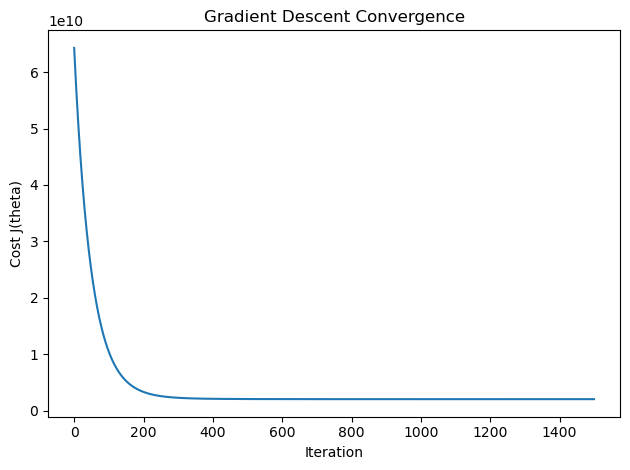


Final parameters (intercept, normalized feature coefficients):
[340412.56301439 109370.05670466  -6500.61509507]
Final training cost: 2,043,282,709.93
Estimated price for a 1650 sq-ft, 3-bedroom house: $293,098.47


In [4]:
"""
Multivariate linear regression with gradient descent.

Predicts house prices from two features (size in sq ft and number of
bedrooms). Features are normalized (z-score), then batch gradient descent
learns the parameters theta. The cost history is plotted to confirm
convergence, and the trained model predicts the price of a sample house.
"""

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Load the data
# The data file sits in the same folder as this script. Each row is: size (sq ft), number of bedrooms, price ($)
# __file__ only exists when running a .py script; Added try for use in Jupyter Notebook
try:
    base_dir = Path(__file__).resolve().parent
except NameError:
    base_dir = Path.cwd()

data_file = base_dir / "Housing_data (2).txt"
data = pd.read_csv(
    data_file,
    header=None,                          # file has no header row
    names=["size", "bedrooms", "price"],
)

X_raw = data[["size", "bedrooms"]].to_numpy(dtype=float)  # features (m x 2)
y = data["price"].to_numpy(dtype=float)                     # targets  (m,)
m = y.size                                                  # number of examples

print("First 10 training examples (size, bedrooms, price):")
print(data.head(10))

# 2. Feature normalization
# Size (~1000s) and bedrooms (~1-5) are on very different scales. Scaling each
# feature to mean 0 and standard deviation 1 lets gradient descent converge
# much faster with a single learning rate.
mu = np.mean(X_raw, axis=0)
sigma = np.std(X_raw, axis=0)
X_norm = (X_raw - mu) / sigma

# Add a column of ones so theta[0] acts as the intercept term.
X = np.column_stack((np.ones(m), X_norm))   # (m x 3)

print("\nFirst 10 normalized examples:")
print(X[:10, 1:])
print("Feature means:", mu)
print("Feature standard deviations:", sigma)

# 3. Cost function
def compute_cost(features, prices, parameters):
    """Mean squared error cost: J(theta) = (1 / 2m) * sum((X @ theta - y)^2)."""
    errors = features @ parameters - prices
    return (errors @ errors) / (2 * prices.size)

# 4. Gradient descent
iterations = 1500   # number of update steps
alpha = 0.01        # learning rate

theta = np.zeros(X.shape[1])        # start with all parameters at 0
J_history = np.zeros(iterations)    # cost after each iteration

for i in range(iterations):
    errors = X @ theta - y                    # prediction error for every example
    theta -= alpha * (X.T @ errors) / m       # simultaneous update of all thetas
    J_history[i] = compute_cost(X, y, theta)  # record cost to check convergence

# Plot the cost versus iteration; it should decrease and level off.
plt.plot(np.arange(iterations), J_history)
plt.xlabel("Iteration")
plt.ylabel("Cost J(theta)")
plt.title("Gradient Descent Convergence")
plt.tight_layout()
plt.show()

print("\nFinal parameters (intercept, normalized feature coefficients):")
print(theta)
print(f"Final training cost: {J_history[-1]:,.2f}")

# 5. Predict the price of a new house
# The new house must be normalized with the SAME mu and sigma as the
# training data before applying theta.
house = np.array([1650, 3], dtype=float)
house_norm = (house - mu) / sigma
house_features = np.concatenate(([1.0], house_norm))  # prepend intercept term
predicted_price = house_features @ theta
print(f"Estimated price for a 1650 sq-ft, 3-bedroom house: ${predicted_price:,.2f}")